# Holdout Backtesting

## Load Backtest Inputs

- **Purpose:** Load and validate inputs for comparing three tuned meta families with one selected primary configuration; run meta modeling first. This notebook is independent of other backtesting notebooks.
- **Input:** Prepared events, split manifest, primary model, meta-model bundle, saved predictions, and market data.
- **Output:** Validated backtest inputs in memory for the following prediction, sizing, simulation, and statistics stages.
- **STRATEGY:** `sentiment_asynchronous` — Choose the matching model artifacts and execution rules.
- **PARTITION:** `holdout` — Use the fixed holdout evaluation window.
- **MANIFEST_PATH:** `data/preprocessing/universe/sp500_2025.csv` — Fix the research universe across stages.
- **DATA_START:** `2025-01-01 UTC` — Include January preparation observations before the research period.
- **RESEARCH_START:** `2025-02-01 UTC` — Set the inclusive research start and the first date in artifact filenames.
- **RESEARCH_END:** `2026-01-01 UTC` — Set the exclusive research end; artifact filenames use the preceding date.
- **settings:** `horizon_bars=780`, `horizontal_multipliers=[5.0, 5.0]`, `max_positions_per_side=10`, `step_size=0.10`, `half_life_minutes=390.0`, `initial_aum=100_000.0`, `broker_fee_bps=1.0`, `slippage_bps=1.0` — Set holding horizon, the total position limit per direction in the single book, sizing, initial capital, and trading costs.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from src.backtesting.backtesting_workflow import (
    load_backtest_inputs, development_predictions, holdout_predictions,
    prepare_bet_sizing, simulate_portfolios, summarize_backtests, save_backtest_results,
)
from src.backtesting.portfolio_management import PortfolioSettings
from src.preprocessing.market_data import ResearchPaths

PROJECT_ROOT = Path.cwd().resolve().parents[2]

STRATEGY = "sentiment_asynchronous"
PARTITION = "holdout"

MANIFEST_PATH = PROJECT_ROOT / "data/preprocessing/universe/sp500_2025.csv"

DATA_START = pd.Timestamp("2025-01-01", tz="UTC")
RESEARCH_START = pd.Timestamp("2025-02-01", tz="UTC")
RESEARCH_END = pd.Timestamp("2026-01-01", tz="UTC")

settings = PortfolioSettings(
    horizon_bars=780,
    horizontal_multipliers=[5.0, 5.0],
    max_positions_per_side=10, step_size=0.10, half_life_minutes=390.0,
    initial_aum=100_000.0, broker_fee_bps=1.0, slippage_bps=1.0,
)

paths = ResearchPaths(PROJECT_ROOT, model_kind="sentiment", start=RESEARCH_START, end=RESEARCH_END)

In [2]:
inputs = load_backtest_inputs(
    paths, settings, strategy=STRATEGY, partition=PARTITION,
    manifest_path=MANIFEST_PATH,
    data_start=DATA_START, end=RESEARCH_END,
)

## Holdout Predictions

- **Purpose:** Validate saved holdout predictions without refitting, tuning, or selecting a winner on holdout.
- **Input:** Family-tagged holdout predictions, fixed event/partition keys, and canonical primary predictions.
- **Output:** Validated predictions in memory; missing/duplicate events, mixed partitions, or inconsistent primary predictions are rejected.

In [3]:
validation_settings = None
splits = None
predictions = holdout_predictions(inputs)

## Bet Sizing

- **Purpose:** Prepare signed signals with training-only price calibration; size from active events and current prices, ranking eligible long/short candidates and reserving only vacant directional slots.
- **Input:** Holdout predictions and development-only calibration data.
- **Output:** In-memory events and aligned calibration tables.

In [4]:
prepared = prepare_bet_sizing(inputs, predictions, splits)

## Portfolio Management

- **Purpose:** Execute independent family/path accounts using a shared completed dollar-bar stream.
- **Input:** Prepared signals/calibration and existing dollar bars.
- **Output:** In-memory ledgers, trades, exposures, and exclusions; progress counts processed bars.
- **Execution:** See the [execution contract](../../../docs/api/backtesting/portfolio_management.md#asynchronous-event-driven-selection) for event-driven reselection, next-bar fills, and final-bar liquidation.
- **Migration:** Recompute backtest results after loading the updated module; existing model artifacts remain reusable.
- **Recording:** Engine v8 keeps UTC minute-last, fill, session-close and terminal/boundary snapshots; all trades and daily results are retained. Intraday statistics use this reduced grid.
- **Decisions:** Select new symbols only initially, on event termination, or after completed liquidation. New registrations update the queue and existing orders without selecting new symbols; limit violations cancel without replacement. Unchanged orders retain their decision time.
- **Reload:** Load the updated modules before rerunning; an already running cell continues with its existing engine.
- **Allocation:** Normalize latest active meta probabilities across retained positions and selected pending entries independently per direction (50% of AUM each). Waiting candidates receive no allocation; their registration and removal do not automatically refill vacant slots.
- **Saved output:** Existing results may predate exit-only reselection (async engine version 8). Restart the kernel and rerun backtesting before comparing performance.


In [5]:
accounts = simulate_portfolios(inputs, prepared, show_progress=True)

Preparing dollar bars


Dollar bars:   0%|          | 0/8899632 [00:00<?, ?bar/s]

## Backtest Statistics

- **Purpose:** Summarize account, classification, and holding metrics without resimulating.
- **Input:** Existing accounts, out-of-sample predictions, and returns for the selected benchmark symbol.
- **Output:** Three model-family statistics tables and three cumulative-return graphs; save `statistics.parquet`, `account.parquet`, and `settings.json` under `data/backtesting/sentiment_asynchronous/holdout`. Detailed trades and intermediate predictions remain in memory.
- **Display:** For each model family (Boosting, Bagging, Random Forest), show only `general_characteristics`, `performance`, `runs`, `implementation_shortfall`, `efficiency`, and `classification_scores` in this code-definition order by path, followed by its path return curves. Rows identify section, metric, and unit; classification metric names use `primary_` or `meta_` prefixes instead of an entity column; no rows or columns are abbreviated. Within each section, retain the original metric order. Other sections remain in the saved statistics. Rerun only the display cell when `statistics` and `accounts` are already available.
- **benchmark_symbol:** `SPY` — Select the market benchmark; local dollar bars must cover the evaluation interval and provide a starting anchor.
- **periods_per_year:** `365.25` — Annualize the calendar-day account series.
- **annual_risk_free_rate:** `0.03` — Use the assumed annual risk-free rate in risk-adjusted statistics.
- **annualized_benchmark_sharpe_ratio:** `1.0` — Set the reference Sharpe for probabilistic Sharpe evaluation.

In [6]:
evaluation_settings = dict(
    benchmark_symbol="SPY",
    periods_per_year=365.25, annual_risk_free_rate=0.03,
    annualized_benchmark_sharpe_ratio=1.0,
)

statistics = summarize_backtests(inputs, predictions, accounts, **evaluation_settings)

### Boosting: Backtest Statistics

holdout
section                  metric                          unit                                        
general_characteristics  start                           timestamp   2025-10-24 13:51:24.469462+00:00
                         end                             timestamp          2025-12-31 21:00:00+00:00
                         average_aum                     USD                             99229.495593
                         leverage                        ratio                               0.987361
                         maximum_dollar_position_size    USD                            125601.565245
                         ratio_of_longs                  ratio                               0.459538
                         frequency_of_bets               count/year                       3700.757804
                         average_holding_period          days                                1.904345
                         annualized_turnover             ratio                             597.358857
                         correlation_to_underlying       ratio                               0.170014
performance              pnl                             USD                              -2001.47134
                         annualized_rate_of_return       ratio                              -0.102483
                         pnl_from_long_positions         USD                             -1073.645495
                         pnl_from_short_positions        USD                              -927.825846
                         hit_ratio                       ratio                               0.469653
                         average_return_from_hits        ratio                               0.000957
                         average_return_from_misses      ratio                                -0.0009
runs                     hhi_positive_returns            ratio                               0.003157
                         hhi_negative_returns            ratio                                0.00244
                         hhi_time_between_bets           ratio                               0.047515
                         percentile_drawdown             ratio                               0.008543
                         percentile_time_under_water     years                               0.002976
implementation_shortfall broker_fees_per_turnover        ratio                                 0.0001
                         average_slippage_per_turnover   ratio                                 0.0001
                         dollar_performance_per_turnover ratio                              -0.000181
                         return_on_execution_costs       ratio                              -0.902875
efficiency               sharpe_ratio                    ratio                              -0.090596
                         annualized_sharpe_ratio         ratio                              -1.731435
                         probabilistic_sharpe_ratio      ratio                               0.118381
classification_scores    primary_accuracy                score                               0.584503
                         primary_precision               score                               0.566309
                         primary_recall                  score                               0.738166
                         primary_f1_score                score                               0.640917
                         primary_negative_log_loss       score                               -0.67107
                         meta_accuracy                   score                               0.585088
                         meta_precision                  score                               0.584937
                         meta_recall                     score                               0.999074
                         meta_f1_score                   score                               0.737868
              

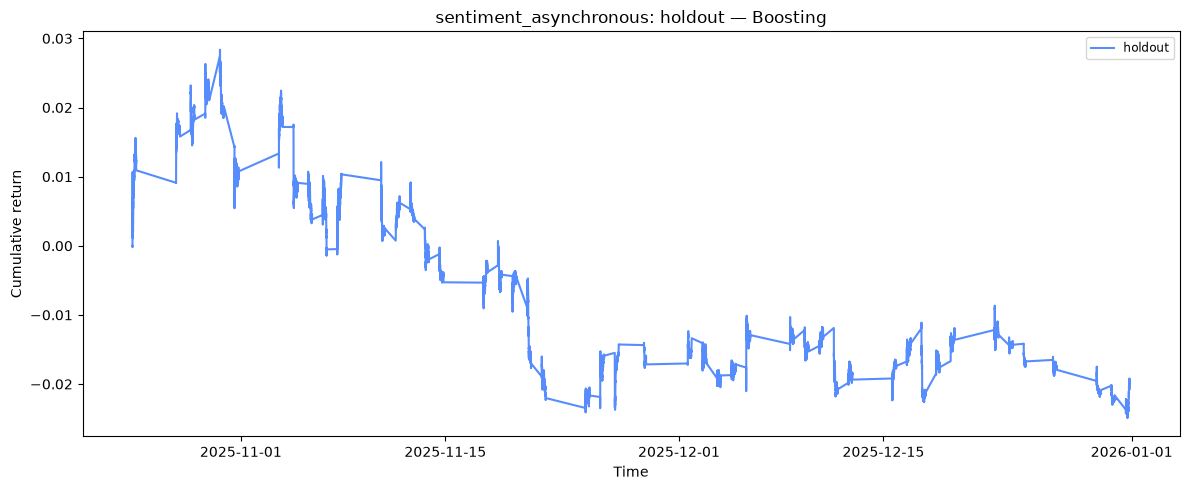

### Bagging: Backtest Statistics

holdout
section                  metric                          unit                                        
general_characteristics  start                           timestamp   2025-10-24 13:51:24.469462+00:00
                         end                             timestamp          2025-12-31 21:00:00+00:00
                         average_aum                     USD                             97424.089401
                         leverage                        ratio                               0.950078
                         maximum_dollar_position_size    USD                            153763.090388
                         ratio_of_longs                  ratio                               0.528409
                         frequency_of_bets               count/year                       3764.932795
                         average_holding_period          days                                 1.45432
                         annualized_turnover             ratio                             692.512333
                         correlation_to_underlying       ratio                              -0.025676
performance              pnl                             USD                              -2602.83977
                         annualized_rate_of_return       ratio                              -0.131547
                         pnl_from_long_positions         USD                               859.978683
                         pnl_from_short_positions        USD                             -3462.818454
                         hit_ratio                       ratio                               0.491477
                         average_return_from_hits        ratio                               0.000995
                         average_return_from_misses      ratio                              -0.001033
runs                     hhi_positive_returns            ratio                                 0.0025
                         hhi_negative_returns            ratio                               0.003476
                         hhi_time_between_bets           ratio                               0.043173
                         percentile_drawdown             ratio                               0.029072
                         percentile_time_under_water     years                               0.073276
implementation_shortfall broker_fees_per_turnover        ratio                                 0.0001
                         average_slippage_per_turnover   ratio                                 0.0001
                         dollar_performance_per_turnover ratio                              -0.000206
                         return_on_execution_costs       ratio                              -1.031592
efficiency               sharpe_ratio                    ratio                              -0.100389
                         annualized_sharpe_ratio         ratio                              -1.918593
                         probabilistic_sharpe_ratio      ratio                               0.094843
classification_scores    primary_accuracy                score                               0.584503
                         primary_precision               score                               0.566309
                         primary_recall                  score                               0.738166
                         primary_f1_score                score                               0.640917
                         primary_negative_log_loss       score                               -0.67107
                         meta_accuracy                   score                               0.584486
                         meta_precision                  score                               0.584496
                         meta_recall                     score                               0.999971
                         meta_f1_score                   score                               0.737761
              

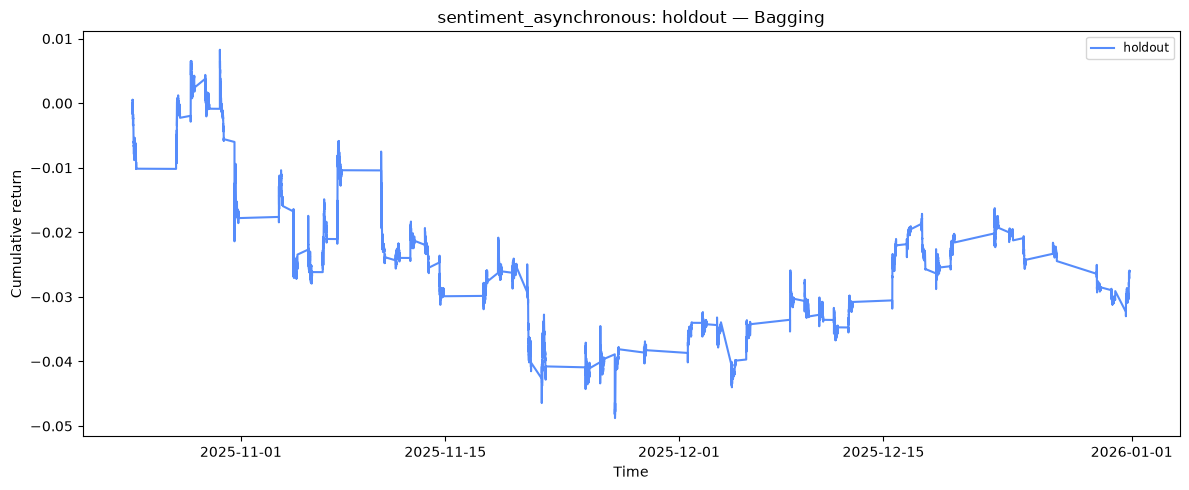

### Random Forest: Backtest Statistics

holdout
section                  metric                          unit                                        
general_characteristics  start                           timestamp   2025-10-24 13:51:24.469462+00:00
                         end                             timestamp          2025-12-31 21:00:00+00:00
                         average_aum                     USD                             90673.668479
                         leverage                        ratio                               0.791131
                         maximum_dollar_position_size    USD                            162167.116304
                         ratio_of_longs                  ratio                               0.573451
                         frequency_of_bets               count/year                       3021.572484
                         average_holding_period          days                                1.065883
                         annualized_turnover             ratio                             739.138418
                         correlation_to_underlying       ratio                               0.164639
performance              pnl                             USD                            -16704.215268
                         annualized_rate_of_return       ratio                              -0.623731
                         pnl_from_long_positions         USD                             -10709.25115
                         pnl_from_short_positions        USD                             -5994.964118
                         hit_ratio                       ratio                               0.474336
                         average_return_from_hits        ratio                                 0.0013
                         average_return_from_misses      ratio                              -0.001771
runs                     hhi_positive_returns            ratio                               0.003387
                         hhi_negative_returns            ratio                               0.028928
                         hhi_time_between_bets           ratio                               0.039624
                         percentile_drawdown             ratio                               0.053741
                         percentile_time_under_water     years                               0.048249
implementation_shortfall broker_fees_per_turnover        ratio                                 0.0001
                         average_slippage_per_turnover   ratio                                 0.0001
                         dollar_performance_per_turnover ratio                              -0.001333
                         return_on_execution_costs       ratio                              -6.664593
efficiency               sharpe_ratio                    ratio                              -0.210479
                         annualized_sharpe_ratio         ratio                              -4.022571
                         probabilistic_sharpe_ratio      ratio                               0.000138
classification_scores    primary_accuracy                score                               0.584503
                         primary_precision               score                               0.566309
                         primary_recall                  score                               0.738166
                         primary_f1_score                score                               0.640917
                         primary_negative_log_loss       score                               -0.67107
                         meta_accuracy                   score                               0.544921
                         meta_precision                  score                               0.657552
                         meta_recall                     score                               0.462067
                         meta_f1_score                   score                               0.542744
              

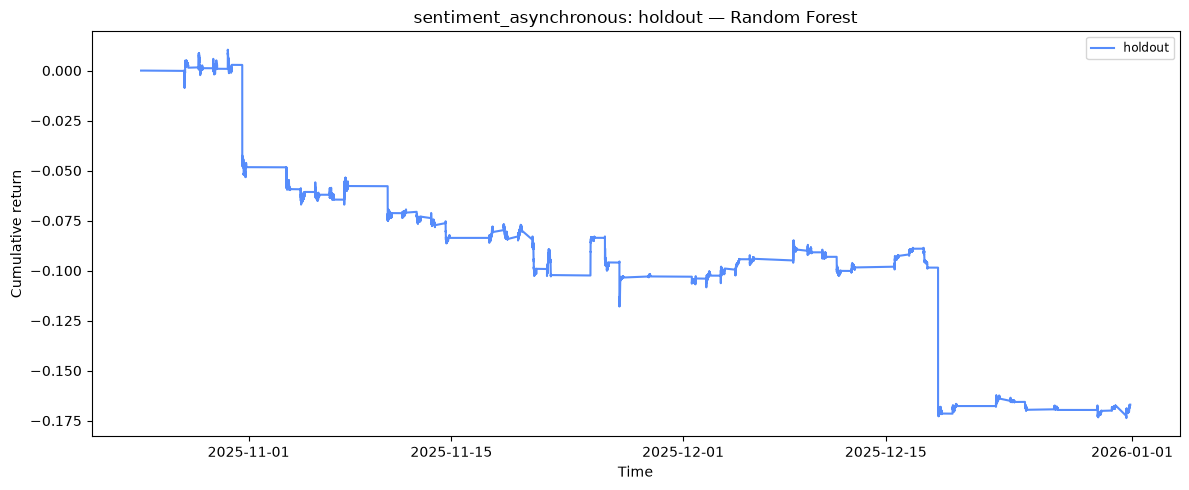

In [7]:
from IPython.display import Markdown

statistics_sections = (
    "general_characteristics", "performance", "runs",
    "implementation_shortfall", "efficiency", "classification_scores",
)
row_index = ["section", "metric", "unit"]

for family in ("boosting", "bagging", "random_forest"):
    family_name = family.replace("_", " ").title()
    family_statistics = statistics.loc[
        statistics["model_family"].eq(family) & statistics["section"].isin(statistics_sections)
    ].sort_values(
        "section", key=lambda values: values.map(statistics_sections.index), kind="stable",
    ).assign(
        metric=lambda frame: frame["metric"].where(
            frame["section"].ne("classification_scores"),
            frame["entity"] + "_" + frame["metric"],
        )
    )
    display_values = family_statistics["value"].astype(object).where(
        family_statistics["unit"].ne("timestamp"), family_statistics["timestamp"],
    )
    display(Markdown(f"### {family_name}: Backtest Statistics"))
    with pd.option_context(
        "display.max_rows", None, "display.max_columns", None,
        "display.max_colwidth", None,
    ):
        display(family_statistics.assign(display_value=display_values).pivot(
            index=row_index, columns="path",
            values="display_value",
        ).reindex(
            pd.MultiIndex.from_frame(family_statistics[row_index].drop_duplicates())
        ).rename_axis(columns=None))

    fig, ax = plt.subplots(figsize=(12, 5))
    for (account_family, path), result in accounts.items():
        if account_family == family:
            ledger = result["ledger"]
            ax.plot(ledger.timestamp, ledger.aum / settings.initial_aum - 1, label=path)
    ax.set(
        title=f"{STRATEGY}: {PARTITION} — {family_name}",
        ylabel="Cumulative return", xlabel="Time",
    )
    ax.legend(fontsize="small", ncol=3)
    fig.tight_layout()
    plt.show()

In [8]:
result_directory = save_backtest_results(
    inputs, statistics, accounts,
    evaluation_settings=evaluation_settings, validation_settings=validation_settings,
)
print(result_directory)

/Users/kwonjunhyuk9/Documents/financial-machine-learning/data/backtesting/sentiment_asynchronous/holdout
